In [ ]:
#Arimaonly

C:\Users\bhara\AppData\Local\Temp\ipykernel_28132\3985701047.py:9: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv('BOAs.csv', parse_dates=['settlementDate'])
C:\Users\bhara\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\bhara\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Best ARIMA order: (1, 0, 0), R2 on last 7 days: 0.197

7-day forecast:
2023-06-12    1.900256
2023-06-13    1.717472
2023-06-14    1.559022
2023-06-15    1.421667
2023-06-16    1.302598
2023-06-17    1.199381
2023-06-18    1.109905
Freq: D, dtype: float64


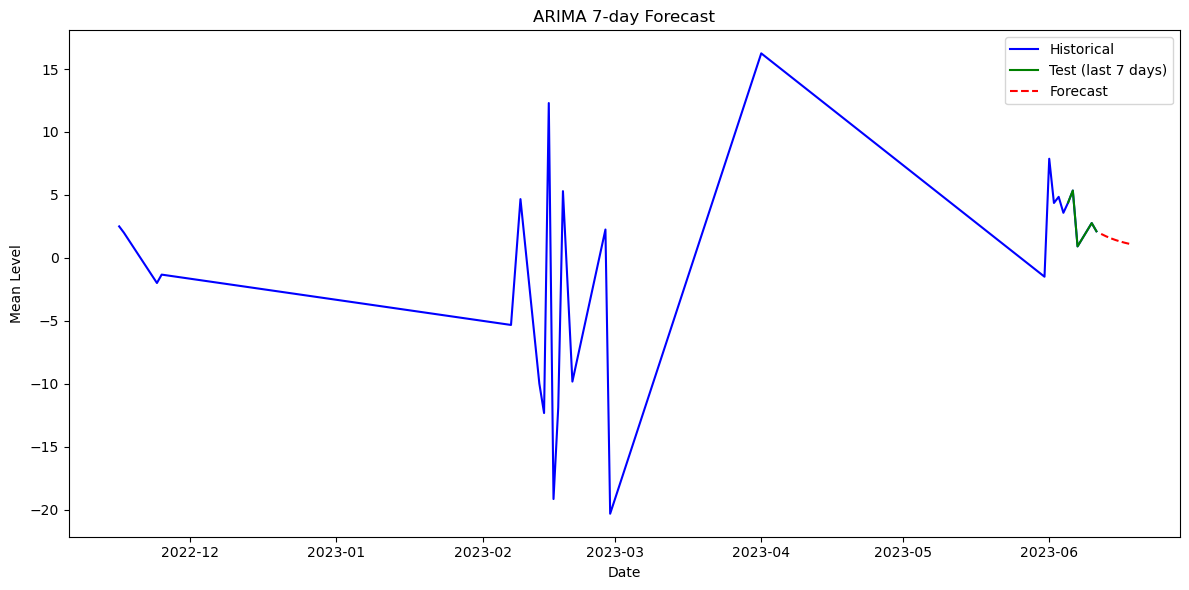

In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import r2_score
import itertools
import matplotlib.pyplot as plt

# 1. Load and preprocess data
df = pd.read_csv('BOAs.csv', parse_dates=['settlementDate'])
df['timeFrom'] = pd.to_datetime(df['timeFrom'], errors='coerce')

# Use the average of levelFrom and levelTo as the signal
df['meanLevel'] = df[['levelFrom', 'levelTo']].mean(axis=1)

# Aggregate to daily mean
daily = (
    df.groupby('settlementDate')['meanLevel']
    .mean()
    .sort_index()
)
# Clean date: Ensure parse and sort
daily.index = pd.to_datetime(daily.index, dayfirst=True)

# Fill missing days with linear interpolation
full_range = pd.date_range(start=daily.index.min(), end=daily.index.max(), freq='D')
series = daily.reindex(full_range)
series = series.interpolate(method='linear')

# 2. Split data into train/test
train = series[:-7]
test = series[-7:]

# 3. Brute force ARIMA model selection to maximize R2
def arima_gridsearch(train, test, pdq_range):
    best_r2 = -np.inf
    best_order = None
    best_model = None
    for order in pdq_range:
        try:
            model = ARIMA(train, order=order)
            model_fit = model.fit()
            pred = model_fit.forecast(steps=len(test))
            score = r2_score(test, pred)
            if score > best_r2:
                best_r2 = score
                best_order = order
                best_model = model_fit
        except Exception:
            continue
    return best_model, best_order, best_r2

pdq_range = list(itertools.product(range(0,3), range(0,2), range(0,3)))
best_model, best_order, best_r2 = arima_gridsearch(train, test, pdq_range)

print(f"Best ARIMA order: {best_order}, R2 on last 7 days: {best_r2:.3f}")

# 4. Retrain ARIMA on all data with best params and forecast next 7 days
final_model = ARIMA(series, order=best_order)
final_fit = final_model.fit()
forecast_7 = final_fit.forecast(steps=7)
forecast_dates = pd.date_range(start=series.index[-1]+pd.Timedelta(days=1), periods=7)
forecast_series = pd.Series(forecast_7.values, index=forecast_dates)

# 5. Output
print("\n7-day forecast:")
print(forecast_series)

# 6. (Optional) Plot
plt.figure(figsize=(12,6))
plt.plot(series, label='Historical', color='blue')
plt.plot(test.index, test.values, label='Test (last 7 days)', color='green')
plt.plot(forecast_series.index, forecast_series.values, 'r--', label='Forecast')
plt.legend()
plt.title('ARIMA 7-day Forecast')
plt.xlabel('Date')
plt.ylabel('Mean Level')
plt.tight_layout()
plt.show()


In [ ]:
#Sarima only

C:\Users\bhara\AppData\Local\Temp\ipykernel_28132\2608645282.py:10: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv('BOAs.csv', parse_dates=['settlementDate'])


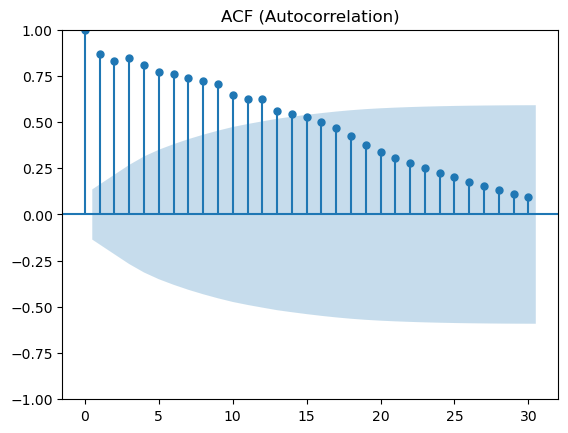

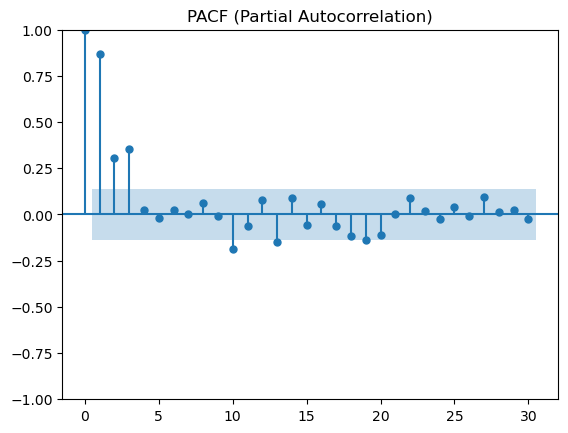

Best SARIMA order: (1, 0, 0), seasonal_order: (0, 0, 0, 7), R²: 0.135

7-day forecast:
2023-06-12    1.838710
2023-06-13    1.601458
2023-06-14    1.394819
2023-06-15    1.214843
2023-06-16    1.058090
2023-06-17    0.921562
2023-06-18    0.802651
Freq: D, dtype: float64


C:\Users\bhara\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


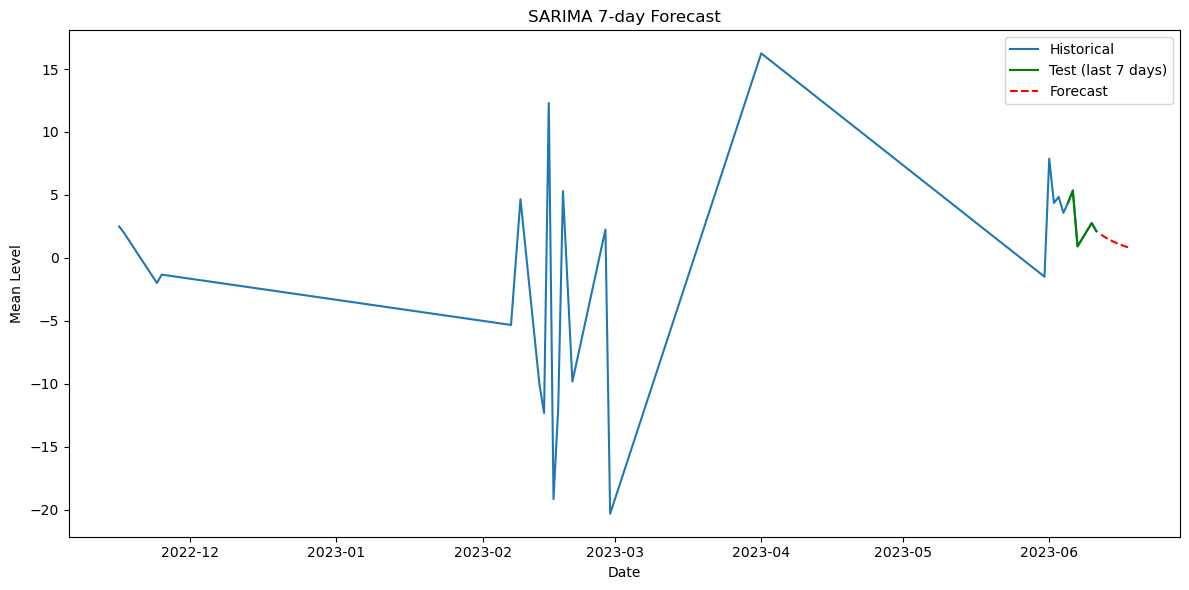

In [7]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Load and preprocess the data
df = pd.read_csv('BOAs.csv', parse_dates=['settlementDate'])
df['timeFrom'] = pd.to_datetime(df['timeFrom'], errors='coerce')
df['meanLevel'] = df[['levelFrom', 'levelTo']].mean(axis=1)
daily = df.groupby('settlementDate')['meanLevel'].mean().sort_index()
daily.index = pd.to_datetime(daily.index, dayfirst=True)
full_range = pd.date_range(start=daily.index.min(), end=daily.index.max(), freq='D')
series = daily.reindex(full_range)
series = series.interpolate('linear')

# Plot ACF and PACF to inspect autocorrelation
plot_acf(series.dropna(), lags=30)
plt.title('ACF (Autocorrelation)')
plt.show()

plot_pacf(series.dropna(), lags=30)
plt.title('PACF (Partial Autocorrelation)')
plt.show()

# 2. Create train/test split
train = series[:-7]
test = series[-7:]

# 3. Grid search for best SARIMA parameters (order, seasonal_order)
p = d = q = range(0, 2)
P = D = Q = range(0, 2)
s = 7  # weekly seasonality (for daily data)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = list(itertools.product(P, D, Q, [s]))

best_r2 = -np.inf
best_order = None
best_seasonal_order = None

for order in pdq:
    for seasonal_order in seasonal_pdq:
        try:
            model = SARIMAX(train,
                            order=order,
                            seasonal_order=seasonal_order,
                            enforce_stationarity=False,
                            enforce_invertibility=False)
            result = model.fit(disp=False)
            pred = result.forecast(steps=7)
            score = r2_score(test, pred)
            if score > best_r2:
                best_r2 = score
                best_order = order
                best_seasonal_order = seasonal_order
        except Exception:
            continue

print(f"Best SARIMA order: {best_order}, seasonal_order: {best_seasonal_order}, R²: {best_r2:.3f}")

# 4. Refit SARIMA on all data and forecast next 7 days
final_model = SARIMAX(series,
                      order=best_order,
                      seasonal_order=best_seasonal_order,
                      enforce_stationarity=False,
                      enforce_invertibility=False)
final_result = final_model.fit(disp=False)
forecast_7 = final_result.forecast(steps=7)
forecast_dates = pd.date_range(start=series.index[-1] + pd.Timedelta(days=1), periods=7)
forecast_series = pd.Series(forecast_7.values, index=forecast_dates)

print("\n7-day forecast:")
print(forecast_series)

# 5. Plot the results
plt.figure(figsize=(12,6))
plt.plot(series, label='Historical')
plt.plot(test.index, test.values, label='Test (last 7 days)', color='green')
plt.plot(forecast_series.index, forecast_series.values, 'r--', label='Forecast')
plt.legend()
plt.title('SARIMA 7-day Forecast')
plt.xlabel('Date')
plt.ylabel('Mean Level')
plt.tight_layout()
plt.show()